Ok essayons de faire marcher git ce matin !
Je vais essayer de récupérer les données des prix de l'immobilier sur Paris à partir d'une url puis de les copier dans un nouveau csv dans notre projet.


# Import des Packages   

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

np.random.seed(123) 

# Récupération des données

C'était fastidieux mais j'ai réussi à trouver l'url )))

In [2]:
url = 'https://static.data.gouv.fr/resources/prix-immobilier-par-commune-ventes-2014-a-2025-dvf-millesime-2026/20261026-112727/prix-immobilier-communes-series-2014-2025.csv'
response = requests.get(url)
if response.status_code == 200:
    with open("data_immo_price.csv", "wb") as file:
        file.write(response.content)

# nétoyage des données

In [3]:
df = pd.read_csv("data_immo_price.csv")
df.head(20)

,code_insee,commune,code_departement,departement,region,population,annee,prix_m2_median,prix_m2_median_appartement,prix_m2_median_maison,prix_m2_median_neuf,ventes,ventes_maisons,ventes_appartements,source
0,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2014,1840.0,1994.0,1672.0,2684.0,139,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
1,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2015,1824.0,1734.0,1873.0,2677.0,166,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
2,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2018,1855.0,1667.0,1992.0,2398.0,206,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
3,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2019,2068.0,1925.0,2133.0,2345.0,214,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
4,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2020,1975.0,2012.0,1894.0,878.0,227,NaN,NaN,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
5,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2021,2189.0,2097.0,2324.0,3546.0,271,151.0,119.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
6,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2022,2419.0,2075.0,2630.0,3528.0,229,130.0,97.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
7,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2023,2322.0,2119.0,2646.0,3634.0,181,93.0,87.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
8,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2024,2276.0,2157.0,2377.0,3822.0,144,75.0,69.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
9,01004,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,15934.0,2025,2485.0,2500.0,2333.0,3722.0,210,95.0,115.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."


In [4]:
df.axes

[RangeIndex(start=0, stop=61327, step=1),
 Index(['code_insee', 'commune', 'code_departement', 'departement', 'region',
        'population', 'annee', 'prix_m2_median', 'prix_m2_median_appartement',
        'prix_m2_median_maison', 'prix_m2_median_neuf', 'ventes',
        'ventes_maisons', 'ventes_appartements', 'source'],
       dtype='str')]

In [5]:
df.shape

(61327, 15)

bon à priori il n'y a que 5208 communes dans le jeu de données. Voyons si on en a un bon paquet en région Parisienne.

In [6]:
df['commune'].nunique()

5208

In [7]:
df['region'].unique()

<ArrowStringArray>
[      'Auvergne-Rhône-Alpes',            'Hauts-de-France',
 'Provence-Alpes-Côte d'Azur',                  'Grand Est',
                  'Occitanie',                  'Normandie',
         'Nouvelle-Aquitaine',        'Centre-Val de Loire',
    'Bourgogne-Franche-Comté',                   'Bretagne',
                      'Corse',           'Pays de la Loire',
              'Île-de-France',                 'Guadeloupe',
                 'Martinique',                     'Guyane',
                 'La Réunion']
Length: 17, dtype: str

L'INSEE ressence 1266 communes en Île de France en 2026, on en a ici 573, soit environ la moitié.

In [8]:
df[df['region'] == 'Île-de-France']['commune'].nunique()

573

In [9]:
df[df['region'] == 'Île-de-France']

,code_insee,commune,code_departement,departement,region,population,annee,prix_m2_median,prix_m2_median_appartement,prix_m2_median_maison,prix_m2_median_neuf,ventes,ventes_maisons,ventes_appartements,source
46358,75101,Paris 1er,75,Paris,Île-de-France,NaN,2021,12970.0,12970.0,NaN,NaN,309,0.0,309.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46359,75101,Paris 1er,75,Paris,Île-de-France,NaN,2022,12936.0,12936.0,NaN,NaN,398,0.0,398.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46360,75101,Paris 1er,75,Paris,Île-de-France,NaN,2023,12953.0,12953.0,NaN,NaN,345,0.0,345.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46361,75101,Paris 1er,75,Paris,Île-de-France,NaN,2024,12586.0,12586.0,NaN,NaN,270,0.0,270.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
46362,75101,Paris 1er,75,Paris,Île-de-France,NaN,2025,12098.0,12098.0,NaN,NaN,291,0.0,291.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60268,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2021,2318.0,2164.0,2836.0,3278.0,199,70.0,129.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60269,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2022,2517.0,2290.0,3206.0,3925.0,216,67.0,149.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60270,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2023,2322.0,2186.0,3265.0,4024.0,155,51.0,103.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."
60271,95680,Villiers-le-Bel,95,Val-d'Oise,Île-de-France,30053.0,2024,2278.0,2091.0,3066.0,3850.0,140,40.0,100.0,"DVF (demandes de valeurs foncières, DGFiP, Lic..."


In [10]:
df.loc[:,['region']]

df.drop_duplicates(subset = 'commune', keep = 'first')
df['code_insee'].isna().sum()
df2 = df.dropna()
df2.size - df.size


-843930

In [11]:
df3 = df.copy()
#df3[['population' + '_log']] = np.log(df.loc[:,['population']])
df3.assign(
    pop_log = np.log(pd.col('population'))
)
df3 = df3.drop(columns = ['population', 'prix_m2_median_appartement','prix_m2_median_maison','prix_m2_median_neuf','ventes', 'ventes_maisons', 'ventes_appartements','source'])

df_annee = {}

for i in df3['annee'].unique():
    df_annee[i] = df3[(df3['annee'] == i) # & (df3['region'] == 'Île-de-France' )
    ]
    df_annee[i].drop(columns = 'annee', inplace = True)
    df_annee[i].sort_values(['prix_m2_median'],inplace = True, ascending = False)
    df_annee[i].reset_index(inplace = True)
    
df_annee[2023].head(50)


/tmp/ipykernel_22976/2208837783.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].drop(columns = 'annee', inplace = True)
/tmp/ipykernel_22976/2208837783.py:14: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].sort_values(['prix_m2_median'],inplace = True, ascending = False)
/tmp/ipykernel_22976/2208837783.py:15: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_annee[i].reset_index(inplace = True)
/tmp/ipykernel_22976/2208837783.py:13: Pandas

,index,code_insee,commune,code_departement,departement,region,prix_m2_median
0,46385,75106,Paris 6e,75,Paris,Île-de-France,15000.0
1,46390,75107,Paris 7e,75,Paris,Île-de-France,14706.0
2,46375,75104,Paris 4e,75,Paris,Île-de-France,13103.0
3,46360,75101,Paris 1er,75,Paris,Île-de-France,12953.0
4,46395,75108,Paris 8e,75,Paris,Île-de-France,12768.0
5,46370,75103,Paris 3e,75,Paris,Île-de-France,12290.0
6,46380,75105,Paris 5e,75,Paris,Île-de-France,12093.0
7,52761,83119,Saint-Tropez,83,Var,Provence-Alpes-Côte d'Azur,11727.0
8,17605,33236,Lège-Cap-Ferret,33,Gironde,Nouvelle-Aquitaine,11668.0
9,46365,75102,Paris 2e,75,Paris,Île-de-France,11660.0


Voyons quelles sont les communes manquantes.

In [12]:
import io
import zipfile
import seaborn as sns

url_pop = f"https://www.data.gouv.fr/api/1/datasets/r/27361ae9-dcab-4312-97a1-48dab5f39218"
r = requests.get(url_pop)
z = zipfile.ZipFile(io.BytesIO(r.content))
print(z.namelist())   # les fichiers du zip

['DS_POPULATIONS_HISTORIQUES_metadata.csv', 'DS_POPULATIONS_HISTORIQUES_data.csv']


In [13]:
#le fichier que nous souhaitons avoir est celui qui ne contient pas les metadata
fichier_data_pop = [n for n in z.namelist() if "metadata" not in n][0]

#on ouvre le zip
with z.open(fichier_data_pop) as f:
    pop = pd.read_csv(f, sep=";", dtype=str)

print(pop.shape)
print(pop.columns.tolist())
pop.head()

(813234, 6)
['FREQ', 'GEO', 'GEO_OBJECT', 'POPREF_MEASURE', 'TIME_PERIOD', 'OBS_VALUE']


,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040


In [14]:
pop_com = pop[(pop["POPREF_MEASURE"] == "PMUN") & (pop["GEO_OBJECT"].isin(["COM", "ARM"]))].copy()
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
0,A,15113,COM,PMUN,2010,197
1,A,14491,COM,PMUN,2007,154
2,A,14761,COM,PMUN,2011,746
3,A,14700,COM,PMUN,2018,663
4,A,15038,COM,PMUN,2013,1040
...,...,...,...,...,...,...
813229,A,16193,COM,PMUN,2015,1016
813230,A,15262,COM,PMUN,2014,534
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [15]:
pop_com['TIME_PERIOD'].sort_values().unique()

pop_com['TIME_PERIOD'] = pd.to_numeric(pop_com['TIME_PERIOD'], errors='coerce').astype('Int64')
pop_com['OBS_VALUE'] = pd.to_numeric(pop_com['OBS_VALUE'], errors='coerce').astype('Int64')

pop_com = pop_com[pop_com['TIME_PERIOD'] >= 2014]

In [16]:
pop_com

,FREQ,GEO,GEO_OBJECT,POPREF_MEASURE,TIME_PERIOD,OBS_VALUE
3,A,14700,COM,PMUN,2018,663
5,A,15038,COM,PMUN,2015,1059
10,A,16270,COM,PMUN,2019,344
11,A,14543,COM,PMUN,2017,2438
13,A,15228,COM,PMUN,2022,461
...,...,...,...,...,...,...
813229,A,16193,COM,PMUN,2015,1016
813230,A,15262,COM,PMUN,2014,534
813231,A,15260,COM,PMUN,2018,110
813232,A,15021,COM,PMUN,2023,665


In [17]:
pop_wide = pop_com.pivot(
    index = 'GEO',
    columns = 'TIME_PERIOD',
    values = 'OBS_VALUE'
)
pop_wide = pop_wide.reset_index().rename(columns={'GEO': 'code_insee'})

pop_per_year = []
Years = [y for y in pop_wide.columns if y != 'code_insee']
for year in Years:
    pop_per_year.append(pop_wide[['code_insee', year]])

pop_per_year[8]

TIME_PERIOD,code_insee,2022
0,01001,859
1,01002,273
2,01004,15554
3,01005,1917
4,01006,114
...,...,...
34901,97420,24855
34902,97421,7333
34903,97422,81964
34904,97423,7113


maintenant qu'on a un dataframe par année on peut comparer avec les communes présentes dans les données de l'immobilier plus haut.

In [18]:
# déja je vais récuperer les liste de communes que j'ai pour chaque année ( je me focus sur 2025)

Merge = pop_per_year[8].merge(
    df_annee[2023],
    left_on = ['code_insee'],
    right_on = ['code_insee'],
    how = 'left'
)

Merge.head()
#Merge['commune'].isna().sum()

,code_insee,2022,index,commune,code_departement,departement,region,prix_m2_median
0,01001,859,NaN,NaN,NaN,NaN,NaN,NaN
1,01002,273,NaN,NaN,NaN,NaN,NaN,NaN
2,01004,15554,7.0,Ambérieu-en-Bugey,01,Ain,Auvergne-Rhône-Alpes,2322.0
3,01005,1917,NaN,NaN,NaN,NaN,NaN,NaN
4,01006,114,NaN,NaN,NaN,NaN,NaN,NaN


observons quelle est la population moyenne dans les communes manquantes

In [19]:
#pop totale manquante

print(f"popuplation totale : {Merge[2023].sum()}")
print(f"population totale manquante : {Merge.loc[Merge['commune'].isna() , 2023].sum()}")

Merge_idf = Merge[Merge['region']=='Île-de-France']


KeyError: 2023

In [ ]:
Merge_idf['commune'].isna().sum()

np.int64(0)

AHAH tout ça pour ça

In [ ]:
Merge_idf[2023].sum()

np.int64(11951439)

In [20]:
df4 = df3.drop(columns = ['code_departement', 'departement']).copy()
df4.head()

,code_insee,commune,region,annee,prix_m2_median
0,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2014,1840.0
1,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2015,1824.0
2,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2018,1855.0
3,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2019,2068.0
4,01004,Ambérieu-en-Bugey,Auvergne-Rhône-Alpes,2020,1975.0


In [21]:
P1 = df4.pivot(
    index = 'code_insee',
    columns = 'annee',
    values = 'prix_m2_median'
)
P1.head()
P2 = df4[['code_insee', 'commune', 'region']].drop_duplicates(subset = 'code_insee')
Prix_immo = P2.merge(
    P1,
    left_on = 'code_insee',
    right_on = 'code_insee',
    how = 'right'
)

In [22]:
Prix_immo.head(20)
Prix_immo[Prix_immo['region']=='Île-de-France'].head()

,code_insee,commune,region,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
3968,75101,Paris 1er,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12970.0,12936.0,12953.0,12586.0,12098.0
3969,75102,Paris 2e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11864.0,11976.0,11660.0,11154.0,11128.0
3970,75103,Paris 3e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12500.0,12547.0,12290.0,11684.0,11959.0
3971,75104,Paris 4e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13028.0,13143.0,13103.0,12596.0,12686.0
3972,75105,Paris 5e,Île-de-France,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12639.0,12706.0,12093.0,11771.0,11667.0


In [23]:
import numpy as np
import pandas as pd
import requests
import s3fs
import geopandas as gpd
import matplotlib.pyplot as plt

In [ ]:

url = ("https://geo.api.gouv.fr/communes?codeRegion=11&type=commune-actuelle,arrondissement-municipal&format=geojson&geometry=contour&fields=code,nom")

communes_geo_distrib = gpd.read_file(url)
communes = communes_geo_distrib[communes_geo_distrib["code"] != "75056"]  # On enlève la commune de Paris (on prend les arrondissement)

In [ ]:
# Copie du DataFrame
prix = Prix_immo.copy()

# Harmoniser les codes INSEE
prix["code_insee"] = prix["code_insee"].astype(str).str.zfill(5)
communes["code"] = communes["code"].astype(str).str.zfill(5)

# Liste des années
annees = list(range(2014, 2026))

# S'assurer que les années sont des colonnes numériques
for year in annees:
    prix[year] = pd.to_numeric(prix[year], errors="coerce")


In [ ]:
vmin = prix[annees].min().min()
vmax = prix[annees].max().max()

/tmp/ipykernel_34254/3465363759.py:57: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


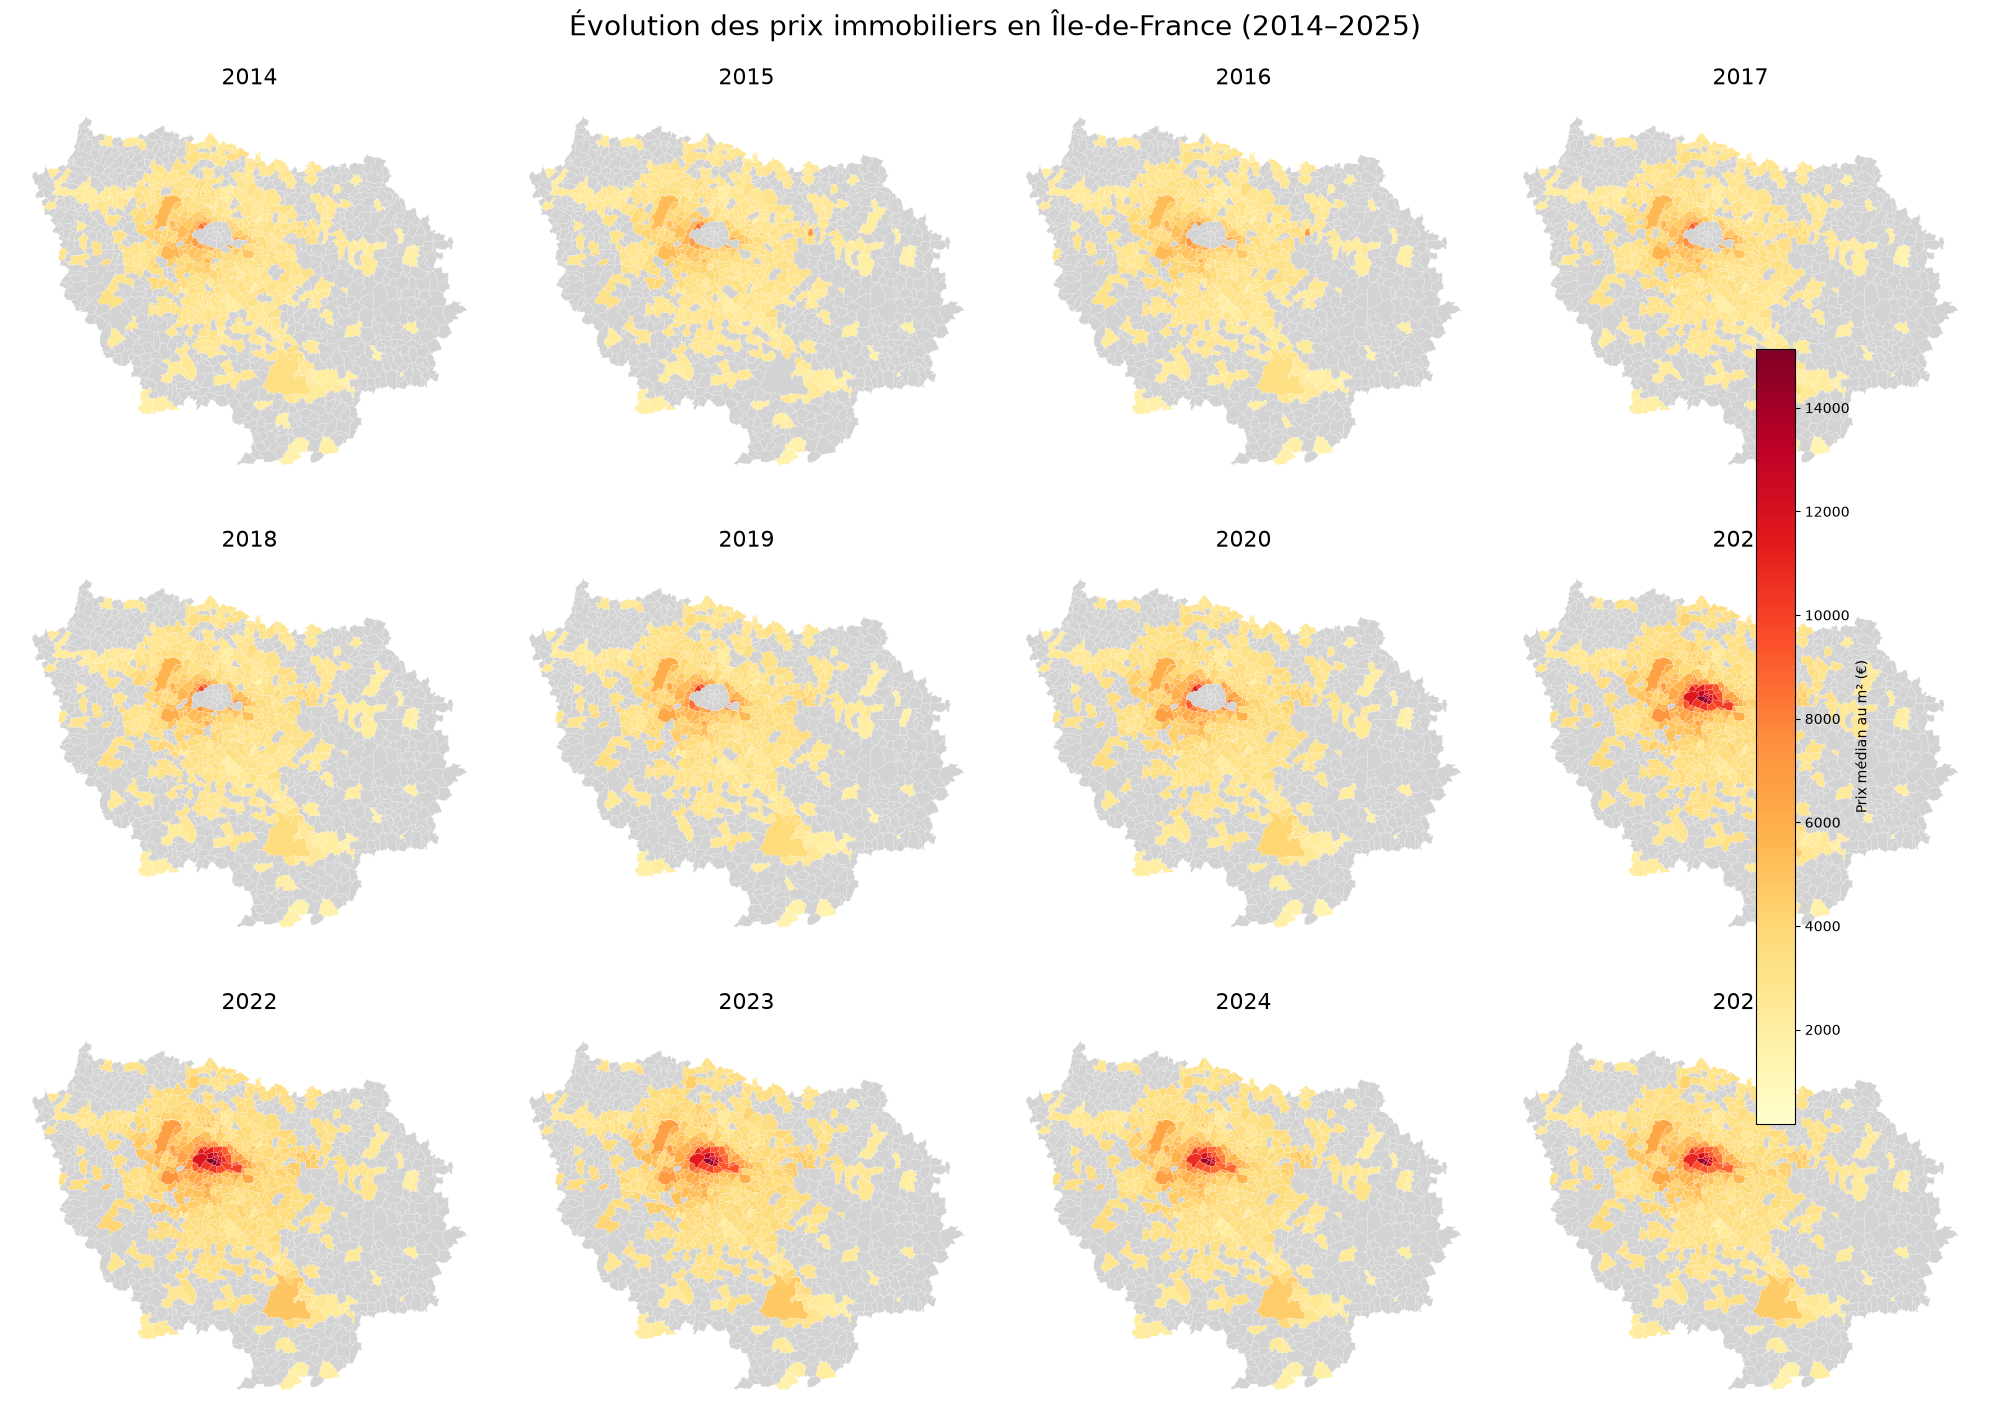

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))

# Échelle de couleurs commune à toutes les années
vmin = prix[annees].min().min()
vmax = prix[annees].max().max()

for ax, year in zip(axes.flatten(), annees):

    # Données de l'année
    year_data = prix[["code_insee", year]].set_index("code_insee")

    # Jointure avec les contours
    gdf = communes.merge(
        year_data,
        left_on="code",
        right_index=True,
        how="left"
    )

    # Tracer la carte
    gdf.plot(
        column=year,
        cmap="YlOrRd",
        ax=ax,
        vmin=vmin,
        vmax=vmax,
        edgecolor="white",
        linewidth=0.1,
        missing_kwds={"color": "lightgrey"}
    )

    ax.set_title(str(year), fontsize=16, pad=10)
    ax.set_axis_off()

# Ajouter une seule légende commune
sm = plt.cm.ScalarMappable(
    cmap="YlOrRd",
    norm=plt.Normalize(vmin=vmin, vmax=vmax)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    orientation="vertical",
    fraction=0.025,
    pad=0.02,
    label="Prix médian au m² (€)"
)

plt.suptitle(
    "Évolution des prix immobiliers en Île-de-France (2014–2025)",
    fontsize=20,
    y=0.98
)

plt.tight_layout()
plt.show()

In [ ]:
test = communes.merge(
    prix[["code_insee", 2023]],
    left_on="code",
    right_on="code_insee",
    how="left"
)

print("Communes avec correspondance INSEE :",
      test["code_insee"].notna().sum())

print("Communes sans correspondance INSEE :",
      test["code_insee"].isna().sum())

print("Communes avec correspondance mais sans prix :",
      test.loc[test["code_insee"].notna(), 2023].isna().sum())

print("Communes avec un prix en 2023 :",
      test[2023].notna().sum())

Communes avec correspondance INSEE : 573
Communes sans correspondance INSEE : 712
Communes avec correspondance mais sans prix : 0
Communes avec un prix en 2023 : 573


In [ ]:
# Communes sans correspondance dans Prix_immo
sans_correspondance = test[
    test["code_insee"].isna()
]

# Communes ayant un code INSEE correspondant mais pas de prix
sans_prix = test[
    test["code_insee"].notna() & test[2014].isna()
]

print("Sans correspondance :")
print(sans_correspondance["code"].head(20).tolist())

print("\nAvec correspondance mais sans prix :")
print(sans_prix["code"].head(20).tolist())

Sans correspondance :
['77001', '77002', '77003', '77004', '77006', '77007', '77008', '77009', '77010', '77011', '77012', '77013', '77015', '77016', '77019', '77020', '77021', '77022', '77023', '77024']

Avec correspondance mais sans prix :
['77058', '77122', '77238', '77249', '77255', '77333', '78172', '78206', '78297', '78299', '78367', '91174', '91200', '91340', '91345', '93029', '93030', '94038', '94041', '94052']


In [ ]:
# Afficher quelques codes des communes sans correspondance
print("Codes géographiques sans correspondance :")
print(sans_correspondance["code"].head(30).tolist())

print("\nCodes de Prix_immo :")
print(prix["code_insee"].head(30).tolist())

print("\nNombre de codes distincts dans Prix_immo :")
print(prix["code_insee"].nunique())

print("\nNombre de codes distincts dans communes :")
print(communes["code"].nunique())

Codes géographiques sans correspondance :
['77001', '77002', '77003', '77004', '77006', '77007', '77008', '77009', '77010', '77011', '77012', '77013', '77015', '77016', '77019', '77020', '77021', '77022', '77023', '77024', '77025', '77026', '77027', '77029', '77030', '77031', '77032', '77033', '77034', '77035']

Codes de Prix_immo :
['01004', '01007', '01014', '01024', '01025', '01027', '01031', '01032', '01033', '01034', '01043', '01049', '01053', '01071', '01072', '01074', '01089', '01093', '01103', '01105', '01109', '01130', '01135', '01138', '01142', '01143', '01148', '01153', '01157', '01159']

Nombre de codes distincts dans Prix_immo :
5255

Nombre de codes distincts dans communes :
1285


In [ ]:
# Codes INSEE des communes géographiques d'IDF
codes_idf = set(communes["code"])

# Codes INSEE de toutes les communes ayant des données immobilières
codes_prix = set(prix["code_insee"])

# Intersection
codes_communs = codes_idf.intersection(codes_prix)

print("Communes en IDF :", len(codes_idf))
print("Communes avec données immobilières en IDF :", len(codes_communs))
print("Communes IDF sans données immobilières :", 
      len(codes_idf - codes_prix))

Communes en IDF : 1285
Communes avec données immobilières en IDF : 573
Communes IDF sans données immobilières : 712


In [ ]:
prix_idf = prix[prix["code_insee"].isin(codes_idf)].copy()

print("Communes IDF dans Prix_immo :", len(prix_idf))
print("Communes avec prix en 2014 :", prix_idf[2014].notna().sum())
print("Communes sans prix en 2014 :", prix_idf[2014].isna().sum())

Communes IDF dans Prix_immo : 573
Communes avec prix en 2014 : 530
Communes sans prix en 2014 : 43


In [ ]:
%pip install lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 34.1 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [24]:
import pandas as pd

url = "https://fgeerolf.com/data/notaires/HistoriquedesprixaumappartementsanciensParispararrdt.html"

tables = pd.read_html(url)

print("Nombre de tableaux :", len(tables))

for i, table in enumerate(tables):
    print(f"\nTableau {i}")
    print(table.head())

ImportError: `Import html5lib` failed.  Use pip, conda, or your preferred package management tool to install the html5lib package.

Ce projet propose une exploration des liens entre la qualité de l'air, et plus précisément les concentrations des principaux polluants atmosphériques, et le coût de la vie en Île-de-France, entendu dans un double sens : le coût de la vie au sens littéral, mesuré par la mortalité, et le coût de la vie au sens économique, mesuré par les prix de l'immobilier. Dans un contexte de tensions climatiques et de hausse du coût de la vie, il nous semble pertinent d'analyser les liens entre ces dimensions en étudiant leurs évolutions et leurs interactions à travers les données. 

Deux raisons principales motivent l'approche de ce projet. D'une part, la qualité de l'air a un effet direct sur la santé : la population exposée présente un risque accru de maladies cardiovasculaires et respiratoires. D'autre part, la qualité de l'air fait partie de l'environnement, urbain comme rural, dans lequel vit la population, et constitue donc l'une des caractéristiques d'un lieu de vie. À ce titre, elle peut à son tour se refléter dans les prix des logements.

Une autre de nos motivations est l'actualité de ce thème dans l'environnement de la manipulation de données. Diverses études, à la fois menées sur le lien entre pollution et mortalité (comme aux [Etats-Unis](https://www.nejm.org/doi/full/10.1056/NEJM199312093292401?referrer=https%3A%2F%2Fscholar.google.com%2F)), mais aussi pollution et prix de l'immobilier, onnt déjà vu le jour. En Île-de-France, l'impact de la pollution est également admis, le site [Airparif](https://www.airparif.fr/effets-sur-la-sante) l'estimant  responsable de 7 900 décès prématurés chaque année dans la région. Dans certaines ville d'[Asie](https://link.springer.com/article/10.1007/s10901-023-10108-z#Sec23), une corrélation très importante est observée entre pollution atmosphérique et prix de l'immobilier, marquée par un phénomène latent : les ménages avec plus de ressources sont prêts à payer plus cher pour avoir des logements en zones moins polluées. En France, les résultats ne sont pas aussi clairs. Une [étude récente menée en 2026](https://www.manda.fr/ressources/articles/qualite-air-paris-arrondissement-loyers) indique que les prix de l'immobilier et la pollution atmosphérique ne seraient pas correlés à Paris. 

Ainsi, si ce sujet est actuel et témoigne d'un véritable enjeu de santé public, il est également l'occasion pour nous de confronter nos résultats à ceux de précédentes études.

##Conclusion

L'objectif de notre projet Python était d'abord d'étudier les indices relatifs à la mortalité, au prix de l'immobilier et à certaines particules polluantes en Île-de-France au cours des dernières années puis de les croiser afin d'observer une potentielle corrélation entre eux.
Nous avions évoqué via l'état de l'art dans l'introduction les résultats issus de la recherche les plus récents commel'impact néfaste de la polution sur la mortalité mis en avant sur le site [Airparif](https://www.airparif.fr/effets-sur-la-sante) ou encore l'effet ambigüe entre la polution et les prix de l'immobilier, négativement corrélées dans certaines villes d'[Asie](https://link.springer.com/article/10.1007/s10901-023-10108-z#Sec23), où la mode semble être à l'exode écologique des ménages aisés, mais annoncé non corrélé en Île-de-France par cette [étude récente menée en 2026](https://www.manda.fr/ressources/articles/qualite-air-paris-arrondissement-loyers).

Voici donc le fruit de notre travail: 
Déjà on a pu constater empiriquement que les vagues de chaleur de 2018, 2019, 2020 et 2022 ainsi que le Covid-19 en 2020 ont largement impacté les courbes de nos indices, notament les facteurs de polution via une large diminution des taux de NO2 et PM5 en 2020 ainsi que des pics de 03 en période de chaleur, ainsi qu'un pic flagrant des taux de mortalité en 2020 et d'autres pics de tendances en période de chaleur.
Concernant les variations des prix, les évenements environementaux ne semblent pas corréler directement les variations locales des prix médian du m2, bien que l'on observe des variations chaque années qui ne semblent pas suivrent de tendance globales.

Notre étude de corélation entre les indices a révélé plusieurs choses: déjà dans toutes nos régréssions entre la polution et la mortalité, aucun coéfficient n'est statistiquement non nul, fait qu'on a intuité en pensant que la poltuion, quelque soit sa forme, est néfaste sur le long terme et n'est probalement pas significative à court termes. Cependant on a aussi conclu que les effets fixes (années, présence d'hopitaux) avaient le rôle le plus important lors des régréssions. 
Enfin les régréssions entre prix de l'immobilier et polutions semblent plus clair, sans effets fixes communaux, tous les facteurs de polution semblent refléter la géographie de l'Île-de-France avec une corrélation positive pour N02 et PM2.5 plus présent au centre de la région où les prix sont les plus haut et négative pour l'O3 plus présent en périphérie ou defacto les prix sont moins élevés. Toutefois, une fois les éffets fixes communaux pris en compte, les coéfficient semblent beaucoup moins significatifs.

Ainsi, la corrélation de la mortailité et de la polution semble faible comme annoncé par cette [étude récente menée en 2026](https://www.manda.fr/ressources/articles/qualite-air-paris-arrondissement-loyers) tandis que les prix de l'immobbiliers s'expliquent surtout par la géographie de la région et moins par les effets de polutions.
